# Evaluate a forecast: can we beat "tomorrow = today"?

**Course project, Big Data Analytics (Arcada), Week 3.**

| | |
|---|---|
| Problem | Forecast Apple (AAPL) tomorrow's closing price |
| Target | tomorrow's log return r(t+1), converted back to a price P(t)·exp(r̂) before scoring |
| Horizon h | 1 trading day |
| Baselines | Naive (tomorrow = today), Always up (direction only) |
| Models | Ridge (simple), XGBoost and CatBoost (advanced) |
| Testing | Walk-forward `TimeSeriesSplit(n_splits=6, test_size=250, gap=h)` |
| Metrics | MAE, MAPE, MASE, MAE ÷ naive, directional accuracy, per fold and mean ± std |

Run all cells top to bottom (**Kernel → Restart & Run All**). Every number and figure in the report is produced here;
figures are saved to `figures/`, tables to `outputs/`.

## 0. Setup

In [1]:
# pip install numpy pandas matplotlib scikit-learn xgboost catboost yfinance
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
random.seed(42); np.random.seed(42)

# ---- Configuration (everything that defines the experiment lives here) ----
TICKER   = "AAPL"
START    = "2018-01-01"
END      = "2026-08-31"       # yfinance treats END as exclusive
H        = 1                  # forecast horizon in trading days
N_SPLITS = 6
TEST_SIZE = 250               # about one trading year per test fold
GAP      = H                  # gap must be >= horizon
SEED     = 42
REFRESH_DATA = False          # True = download again even if data/ has a cached copy

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Naive": "#444444", "Ridge": "#2a7ad5", "XGBoost": "#ec6a35",
          "CatBoost": "#1fb27f", "Always up": "#9b59b6"}

## 1. Data

Daily prices from Yahoo Finance via `yfinance` (`auto_adjust=True`, so prices are adjusted for splits and dividends).
The first run downloads the data and caches it in `data/`; later runs reuse the cache, so results do not change
if Yahoo revises its adjusted prices.

In [2]:
CACHE = f"data/{TICKER}_daily_{START}_{END}.csv"

def load_prices():
    if os.path.exists(CACHE) and not REFRESH_DATA:
        d = pd.read_csv(CACHE, index_col=0, parse_dates=True)
        print(f"Loaded cached data: {CACHE}")
        return d
    import yfinance as yf
    d = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
    if isinstance(d.columns, pd.MultiIndex):          # flatten yfinance MultiIndex
        d.columns = d.columns.get_level_values(0)
    d = d.loc[:, ~d.columns.duplicated()].copy()
    d.to_csv(CACHE)
    print(f"Downloaded {TICKER} and cached to {CACHE}")
    return d

df = load_prices()[["Open", "High", "Low", "Close", "Volume"]].sort_index()
print(df.shape, df.index.min().date(), "to", df.index.max().date())
print("Missing values:", int(df.isna().sum().sum()), "| duplicated dates:", int(df.index.duplicated().sum()))
df.head()

Downloaded AAPL and cached to data/AAPL_daily_2018-01-01_2026-08-31.csv
(2176, 5) 2018-01-02 to 2026-08-28
Missing values: 0 | duplicated dates: 0


Price,Open,High,Low,Close,Volume
Date,,,,,
2018-01-02,39.741914,40.241724,39.531711,40.232380,102223600
2018-01-03,40.295432,40.767217,40.162307,40.225365,118071600
2018-01-04,40.297780,40.514989,40.190346,40.412224,89738400
2018-01-05,40.507979,40.958741,40.416892,40.872326,94640000
2018-01-08,40.720516,41.014796,40.622419,40.720516,82271200


## 2. Features and target (only information known at day t)

All features use **trailing** windows (`shift(k)` and `rolling(k)`, never `center=True`), so a feature on day *t* only uses
data up to day *t*. The target is tomorrow's log return `r(t+1) = ln(P(t+1)/P(t))`.

In [3]:
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))        # r(t)

def build_features(d):
    f = pd.DataFrame(index=d.index)
    r = d["log_return"]
    for lag in range(10):                                           # lagged returns r(t)...r(t-9)
        f[f"r_lag{lag}"] = r.shift(lag)
    f["vol5"]  = r.rolling(5).std()                                 # volatility
    f["vol20"] = r.rolling(20).std()
    f["mom5"]  = r.rolling(5).sum()                                 # momentum
    f["mom20"] = r.rolling(20).sum()
    f["dist_ma20"] = np.log(d["Close"] / d["Close"].rolling(20).mean())   # mean reversion
    f["dow"] = d.index.dayofweek                                    # day of week (0 = Monday)
    return f

feats = build_features(df)
feature_cols = list(feats.columns)

df_all = feats.copy()
df_all["target"] = df["log_return"].shift(-H)                       # r(t+h)
df_all["Close"] = df["Close"]
data = df_all.dropna().copy()                                       # drop incomplete rows at both ends

X, y, close = data[feature_cols], data["target"], data["Close"]
print("Rows:", len(data), "| features:", len(feature_cols))
print("Modelling period:", data.index.min().date(), "to", data.index.max().date())

Rows: 2155 | features: 16
Modelling period: 2018-01-31 to 2026-08-27


### Leakage check

A feature is safe if its value on day *t* does not change when all later days are removed. We recompute the features on
truncated data for 25 random days and compare.

In [4]:
rng = np.random.default_rng(0)
check_days = rng.choice(np.arange(60, len(df) - 5), size=25, replace=False)
max_diff = 0.0
for i in check_days:
    trunc = df.iloc[: i + 1]                         # history up to and including day i
    f_trunc = build_features(trunc).iloc[-1]
    f_full  = feats.iloc[i]
    max_diff = max(max_diff, float(np.nanmax(np.abs(f_trunc.values - f_full.values))))
print(f"Largest difference between truncated and full-history features: {max_diff:.2e}")
assert max_diff < 1e-12, "A feature uses future data!"
print("OK: no feature looks ahead.")

Largest difference between truncated and full-history features: 0.00e+00
OK: no feature looks ahead.


## 3. Walk-forward folds

`TimeSeriesSplit` with an expanding training window. Each test fold is the next ~250 trading days after its training
data, with a gap of `h` days between them. **One split object is shared by every model and baseline**, so all of them
are scored on identical days.

In [5]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_SIZE, gap=GAP)

fold_table = []
for k, (tr, te) in enumerate(tscv.split(X), start=1):
    fold_table.append({"Fold": k, "Train rows": len(tr),
                       "Train end": X.index[tr[-1]].date(),
                       "Test start": X.index[te[0]].date(),
                       "Test end": X.index[te[-1]].date(),
                       "Test rows": len(te)})
fold_table = pd.DataFrame(fold_table)
fold_table.to_csv("outputs/fold_table.csv", index=False)
fold_table

,Fold,Train rows,Train end,Test start,Test end,Test rows
0,1,654,2020-09-03,2020-09-08,2021-09-02,250
1,2,904,2021-09-01,2021-09-03,2022-08-31,250
2,3,1154,2022-08-30,2022-09-01,2023-08-30,250
3,4,1404,2023-08-29,2023-08-31,2024-08-28,250
4,5,1654,2024-08-27,2024-08-29,2025-08-28,250
5,6,1904,2025-08-27,2025-08-29,2026-08-27,250


### Figure 1: the data, with training and test periods marked

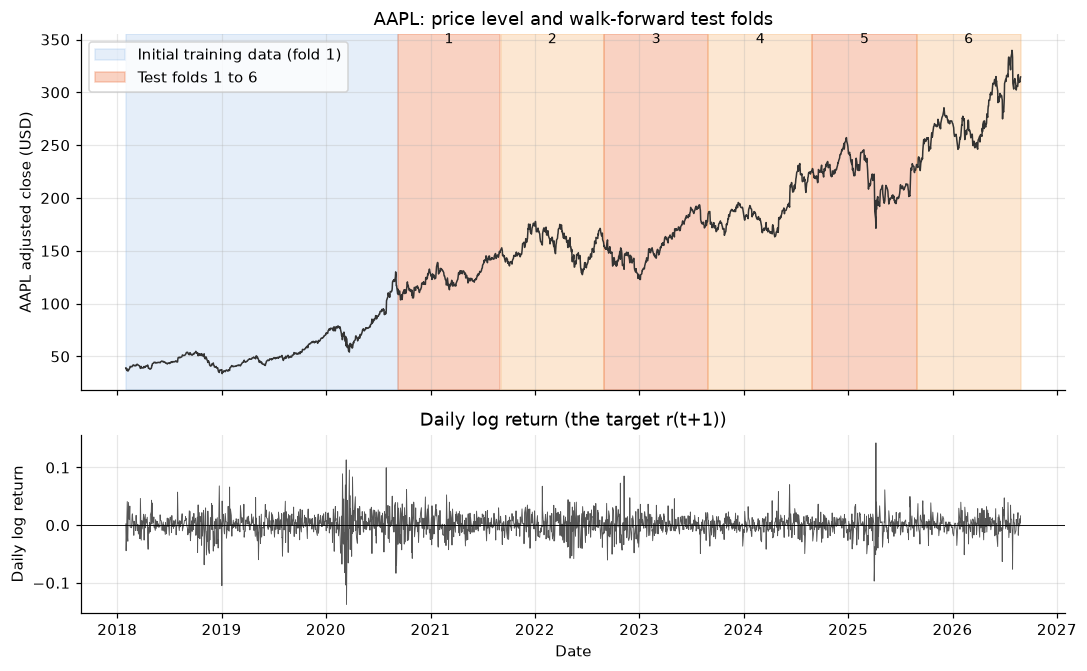

In [6]:
first_test_start = X.index[next(iter(tscv.split(X)))[1][0]]
fig, ax = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})

ax[0].plot(close.index, close, color="#333333", lw=1)
ax[0].axvspan(close.index[0], first_test_start, color="#2a7ad5", alpha=0.12, label="Initial training data (fold 1)")
shades = ["#ec6a35", "#f6b26b"]
for k, row in fold_table.iterrows():
    ax[0].axvspan(pd.Timestamp(row["Test start"]), pd.Timestamp(row["Test end"]),
                  color=shades[k % 2], alpha=0.30,
                  label="Test folds 1 to 6" if k == 0 else None)
    ax[0].text(pd.Timestamp(row["Test start"]) + (pd.Timestamp(row["Test end"]) - pd.Timestamp(row["Test start"])) / 2,
               close.max() * 1.02, f"{k+1}", ha="center", fontsize=9)
ax[0].set_ylabel(f"{TICKER} adjusted close (USD)")
ax[0].set_title(f"{TICKER}: price level and walk-forward test folds")
ax[0].legend(loc="upper left")

ax[1].plot(y.index, y, color="#555555", lw=0.6)
ax[1].axhline(0, color="black", lw=0.6)
ax[1].set_ylabel("Daily log return")
ax[1].set_xlabel("Date")
ax[1].set_title("Daily log return (the target r(t+1))")
plt.tight_layout()
plt.savefig("figures/fig1_data_and_folds.png", dpi=200)
plt.show()

## 4. Metrics

* **MAE**: the average miss in USD. Grows with the price level.
* **MAPE**: the average miss in % of the price (safe here because prices are never near 0; never used on returns).
* **MASE**: test MAE ÷ MAE of the naive forecast on the *training* fold (in-sample scale).
* **MAE ÷ naive** (relative MAE): test MAE ÷ naive MAE on the *same test fold*. Below 1 = better than "no change". **This is the key number.**
* **Directional accuracy**: share of days with the up/down call right, next to the "always up" baseline.

All price metrics are computed on prices rebuilt as `P(t)·exp(r̂)` (descaled), so every model is scored on the same scale.

In [7]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def directional_accuracy(actual_ret, pred_ret):
    return np.mean(np.sign(actual_ret) == np.sign(pred_ret)) * 100

# Model settings (the same in every fold). Models are fitted on the standardised return target.
def make_models():
    return {
        "Ridge": Ridge(alpha=1.0),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3,
                                min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
                                reg_lambda=5.0, objective="reg:squarederror",
                                random_state=SEED),
        "CatBoost": CatBoostRegressor(iterations=500, depth=4, learning_rate=0.03,
                                      l2_leaf_reg=5, loss_function="RMSE",
                                      random_seed=SEED, verbose=0),
    }

## 5. Walk-forward evaluation

In every fold: fit the scalers on the **training fold only**, fit each model, predict the standardised return, undo
the scaling (`r̂ = ẑ·σ + μ`), and rebuild the price from the last *known* close (`P̂ = P(t)·exp(r̂)`).
The naive forecast is `r̂ = 0`, i.e. `P̂ = P(t)`.

In [8]:
results = []
preds = {}            # keep test-fold predictions for the forecast-vs-actual figure

for fold, (tr, te) in enumerate(tscv.split(X), start=1):
    print(f"Fold {fold}: train {len(tr)} rows, test {len(te)} rows "
          f"({X.index[te[0]].date()} to {X.index[te[-1]].date()})")

    X_tr, X_te = X.iloc[tr], X.iloc[te]
    y_tr, y_te = y.iloc[tr].to_numpy(), y.iloc[te].to_numpy()
    P_tr, P_te = close.iloc[tr].to_numpy(), close.iloc[te].to_numpy()   # last KNOWN prices P(t)

    P_act_te = P_te * np.exp(y_te)                       # realised P(t+1)
    P_act_tr = P_tr * np.exp(y_tr)

    # --- baselines -------------------------------------------------------------
    naive_test_mae  = mean_absolute_error(P_act_te, P_te)             # naive: P_hat = P(t)
    naive_train_mae = mean_absolute_error(P_act_tr, P_tr)             # MASE denominator
    always_up = np.mean(y_te > 0) * 100

    results.append({"Fold": fold, "Model": "Naive", "MAE": naive_test_mae,
                    "MAPE": mape(P_act_te, P_te), "MASE": naive_test_mae / naive_train_mae,
                    "Relative_MAE": 1.0, "Direction_Accuracy": np.nan, "Always_Up": always_up})

    # --- scaling with TRAINING statistics only -----------------------------------
    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
    mu, sd = y_tr.mean(), y_tr.std(ddof=1)
    y_tr_s = (y_tr - mu) / sd

    # --- models ------------------------------------------------------------------
    for name, model in make_models().items():
        model.fit(X_tr_s, y_tr_s)
        r_hat = model.predict(X_te_s) * sd + mu                        # descale
        P_hat = P_te * np.exp(r_hat)                                    # rebuild price
        mae = mean_absolute_error(P_act_te, P_hat)
        results.append({"Fold": fold, "Model": name, "MAE": mae,
                        "MAPE": mape(P_act_te, P_hat), "MASE": mae / naive_train_mae,
                        "Relative_MAE": mae / naive_test_mae,
                        "Direction_Accuracy": directional_accuracy(y_te, r_hat),
                        "Always_Up": always_up})
        preds[(fold, name)] = pd.Series(P_hat, index=X_te.index)

    preds[(fold, "Actual")] = pd.Series(P_act_te, index=X_te.index)
    preds[(fold, "Naive")]  = pd.Series(P_te, index=X_te.index)

results_df = pd.DataFrame(results)
results_df.to_csv("outputs/results_per_fold.csv", index=False)
results_df.round(3)

Fold 1: train 654 rows, test 250 rows (2020-09-08 to 2021-09-02)
Fold 2: train 904 rows, test 250 rows (2021-09-03 to 2022-08-31)
Fold 3: train 1154 rows, test 250 rows (2022-09-01 to 2023-08-30)
Fold 4: train 1404 rows, test 250 rows (2023-08-31 to 2024-08-28)
Fold 5: train 1654 rows, test 250 rows (2024-08-29 to 2025-08-28)
Fold 6: train 1904 rows, test 250 rows (2025-08-29 to 2026-08-27)


,Fold,Model,MAE,MAPE,MASE,Relative_MAE,Direction_Accuracy,Always_Up
0,1,Naive,1.723,1.403,1.977,1.000,NaN,52.0
1,1,Ridge,1.840,1.495,2.112,1.068,49.6,52.0
2,1,XGBoost,1.971,1.609,2.262,1.144,48.4,52.0
3,1,CatBoost,1.805,1.471,2.072,1.048,52.4,52.0
4,2,Naive,2.303,1.496,2.066,1.000,NaN,50.4
5,2,Ridge,2.339,1.517,2.098,1.015,54.0,50.4
6,2,XGBoost,2.284,1.484,2.049,0.992,54.4,50.4
7,2,CatBoost,2.293,1.489,2.057,0.996,54.0,50.4
8,3,Naive,2.010,1.317,1.465,1.000,NaN,52.4
9,3,Ridge,2.077,1.364,1.514,1.034,47.6,52.4


## 6. Results: per fold, then mean ± std across folds

In [9]:
metric_cols = ["MAE", "MAPE", "MASE", "Relative_MAE", "Direction_Accuracy"]
order = ["Naive", "Ridge", "XGBoost", "CatBoost"]

g = results_df.groupby("Model")[metric_cols]
mean_, std_ = g.mean().loc[order], g.std().loc[order]
summary = pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean_[c], std_[c])] for c in metric_cols},
                       index=order)
summary.loc["Naive", "Direction_Accuracy"] = "n/a"

au = results_df.groupby("Fold")["Always_Up"].first()
print("Always-up directional accuracy per fold:\n", au.round(1).to_string())
print(f"\nAlways-up mean ± std: {au.mean():.2f} ± {au.std():.2f} %\n")

summary.to_csv("outputs/results_summary.csv")
summary

Always-up directional accuracy per fold:
 Fold
1    52.0
2    50.4
3    52.4
4    55.6
5    53.2
6    54.0

Always-up mean ± std: 52.93 ± 1.78 %



,MAE,MAPE,MASE,Relative_MAE,Direction_Accuracy
Naive,2.312 ± 0.534,1.276 ± 0.171,1.737 ± 0.292,1.000 ± 0.000,n/a
Ridge,2.388 ± 0.524,1.322 ± 0.180,1.798 ± 0.303,1.035 ± 0.020,50.000 ± 2.249
XGBoost,2.413 ± 0.508,1.341 ± 0.202,1.823 ± 0.329,1.049 ± 0.052,51.267 ± 2.634
CatBoost,2.361 ± 0.529,1.305 ± 0.177,1.775 ± 0.293,1.023 ± 0.021,50.800 ± 2.319


In [10]:
# Per-fold tables for the report
for metric in ["Relative_MAE", "MAE", "MAPE", "Direction_Accuracy"]:
    t = results_df.pivot(index="Fold", columns="Model", values=metric)[order]
    if metric == "Direction_Accuracy":
        t = t.drop(columns="Naive"); t["Always up"] = au
    print(metric); print(t.round(3)); print()

Relative_MAE
Model  Naive  Ridge  XGBoost  CatBoost
Fold                                  
1        1.0  1.068    1.144     1.048
2        1.0  1.015    0.992     0.996
3        1.0  1.034    1.055     1.047
4        1.0  1.039    1.032     1.012
5        1.0  1.042    1.048     1.014
6        1.0  1.014    1.022     1.020

MAE
Model  Naive  Ridge  XGBoost  CatBoost
Fold                                  
1      1.723  1.840    1.971     1.805
2      2.303  2.339    2.284     2.293
3      2.010  2.077    2.120     2.105
4      1.955  2.031    2.018     1.979
5      2.758  2.874    2.889     2.795
6      3.126  3.169    3.194     3.189

MAPE
Model  Naive  Ridge  XGBoost  CatBoost
Fold                                  
1      1.403  1.495    1.609     1.471
2      1.496  1.517    1.484     1.489
3      1.317  1.364    1.390     1.379
4      1.036  1.076    1.070     1.050
5      1.277  1.332    1.339     1.293
6      1.128  1.145    1.152     1.150

Direction_Accuracy
Model  Ridge  XGBoos

In [11]:
# How often does each model beat the baselines?
m = results_df[results_df["Model"] != "Naive"].copy()
m["Beats naive (MAE ÷ naive < 1)"] = m["Relative_MAE"] < 1
m["Beats always-up"] = m["Direction_Accuracy"] > m["Always_Up"]
beat = m.groupby("Model")[["Beats naive (MAE ÷ naive < 1)", "Beats always-up"]].sum().astype(int)
beat["Folds"] = N_SPLITS
beat.to_csv("outputs/folds_beating_baselines.csv")
beat

,Beats naive (MAE ÷ naive < 1),Beats always-up,Folds
Model,,,
CatBoost,1,2,6
Ridge,0,1,6
XGBoost,1,1,6


### Figure 2: forecast vs actual for one test period

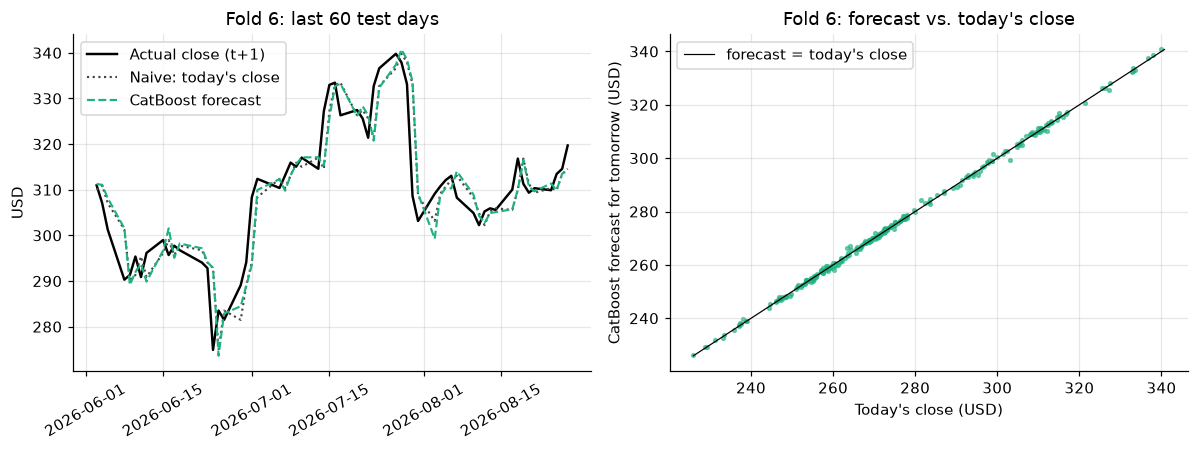

In [12]:
FOLD_PLOT, N_DAYS = N_SPLITS, 60                     # last 60 test days of the last fold
a = preds[(FOLD_PLOT, "Actual")].iloc[-N_DAYS:]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].plot(a.index, a, color="black", lw=1.6, label="Actual close (t+1)")
ax[0].plot(a.index, preds[(FOLD_PLOT, "Naive")].loc[a.index], color=COLORS["Naive"], ls=":", lw=1.4, label="Naive: today's close")
ax[0].plot(a.index, preds[(FOLD_PLOT, "CatBoost")].loc[a.index], color=COLORS["CatBoost"], ls="--", lw=1.4, label="CatBoost forecast")
ax[0].set_title(f"Fold {FOLD_PLOT}: last {N_DAYS} test days")
ax[0].set_ylabel("USD"); ax[0].tick_params(axis="x", rotation=30); ax[0].legend()

xx = preds[(FOLD_PLOT, "Naive")]; yy = preds[(FOLD_PLOT, "CatBoost")]
ax[1].scatter(xx, yy, s=6, color=COLORS["CatBoost"], alpha=0.6)
lims = [min(xx.min(), yy.min()), max(xx.max(), yy.max())]
ax[1].plot(lims, lims, color="black", lw=0.8, label="forecast = today's close")
ax[1].set_title(f"Fold {FOLD_PLOT}: forecast vs. today's close")
ax[1].set_xlabel("Today's close (USD)"); ax[1].set_ylabel("CatBoost forecast for tomorrow (USD)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/fig2_forecast_vs_actual.png", dpi=200); plt.show()

### Figure 3: a metric per fold, every model vs. the baseline

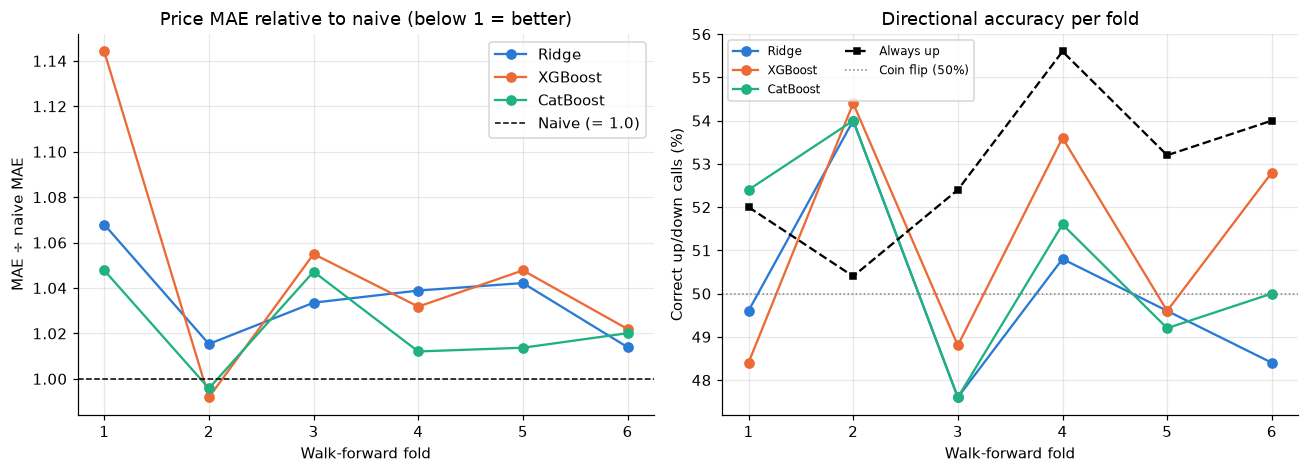

In [13]:
rel = results_df[results_df["Model"] != "Naive"].pivot(index="Fold", columns="Model", values="Relative_MAE")[["Ridge", "XGBoost", "CatBoost"]]
dacc = results_df[results_df["Model"] != "Naive"].pivot(index="Fold", columns="Model", values="Direction_Accuracy")[["Ridge", "XGBoost", "CatBoost"]]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for c in rel.columns:
    ax[0].plot(rel.index, rel[c], marker="o", color=COLORS[c], label=c)
ax[0].axhline(1.0, color="black", ls="--", lw=1, label="Naive (= 1.0)")
ax[0].set_title("Price MAE relative to naive (below 1 = better)")
ax[0].set_xlabel("Walk-forward fold"); ax[0].set_ylabel("MAE ÷ naive MAE"); ax[0].legend()

for c in dacc.columns:
    ax[1].plot(dacc.index, dacc[c], marker="o", color=COLORS[c], label=c)
ax[1].plot(au.index, au.values, color="black", ls="--", marker="s", ms=4, label="Always up")
ax[1].axhline(50, color="grey", ls=":", lw=1, label="Coin flip (50%)")
ax[1].set_title("Directional accuracy per fold")
ax[1].set_xlabel("Walk-forward fold"); ax[1].set_ylabel("Correct up/down calls (%)"); ax[1].legend(ncol=2, fontsize=8)
for a_ in ax: a_.set_xticks(rel.index)
plt.tight_layout(); plt.savefig("figures/fig3_metric_per_fold.png", dpi=200); plt.show()

### Figure 4: model comparison across folds (dots = folds, bar = mean)

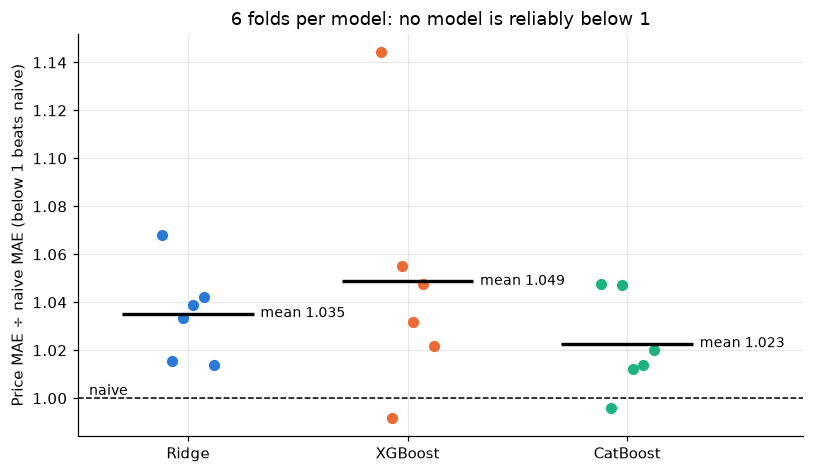

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
names = ["Ridge", "XGBoost", "CatBoost"]
for i, n in enumerate(names):
    v = rel[n].values
    jitter = np.linspace(-0.12, 0.12, len(v))
    ax.scatter(np.full(len(v), i) + jitter, v, color=COLORS[n], s=40, zorder=3)
    ax.hlines(v.mean(), i - 0.3, i + 0.3, color="black", lw=2.2, zorder=4)
    ax.text(i + 0.33, v.mean(), f"mean {v.mean():.3f}", va="center", fontsize=9)
ax.axhline(1.0, color="black", ls="--", lw=1)
ax.text(-0.45, 1.0, "naive", va="bottom", fontsize=9)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.set_xlim(-0.5, len(names) - 0.2)
ax.set_ylabel("Price MAE ÷ naive MAE (below 1 beats naive)")
ax.set_title(f"{N_SPLITS} folds per model: no model is reliably below 1")
plt.tight_layout(); plt.savefig("figures/fig4_model_comparison.png", dpi=200); plt.show()

## 7. Conclusion (computed from the results above)

In [15]:
best = mean_["Relative_MAE"].drop("Naive").idxmin()
print(f"Best model by mean MAE ÷ naive: {best} ({mean_.loc[best, 'Relative_MAE']:.3f}).")
for n in names:
    print(f"  {n:9s} MAE ÷ naive = {mean_.loc[n, 'Relative_MAE']:.3f} ± {std_.loc[n, 'Relative_MAE']:.3f}; "
          f"beats naive in {int(beat.loc[n].iloc[0])}/{N_SPLITS} folds; "
          f"direction right {mean_.loc[n, 'Direction_Accuracy']:.1f}% vs always-up {au.mean():.1f}%")
if (mean_.loc[names, "Relative_MAE"] >= 1).all():
    print("\nNo model beats the naive forecast on average -> do not use the models; keep 'no change'.")
else:
    print("\nAt least one model beats naive on average: check every fold (and for leaks) before trusting it.")

Best model by mean MAE ÷ naive: CatBoost (1.023).
  Ridge     MAE ÷ naive = 1.035 ± 0.020; beats naive in 0/6 folds; direction right 50.0% vs always-up 52.9%
  XGBoost   MAE ÷ naive = 1.049 ± 0.052; beats naive in 1/6 folds; direction right 51.3% vs always-up 52.9%
  CatBoost  MAE ÷ naive = 1.023 ± 0.021; beats naive in 1/6 folds; direction right 50.8% vs always-up 52.9%

No model beats the naive forecast on average -> do not use the models; keep 'no change'.


## Reference: results from the author's run (6 folds, data 2018-01-02 to end of Aug 2026)

Your numbers should match these to the third decimal if the cached data are the same (a different download can shift
them slightly because Yahoo revises adjusted prices).

| Model | MAE (USD) | MAPE (%) | MASE | MAE ÷ naive | Up/down right (%) |
|---|---|---|---|---|---|
| Naive | 2.312 ± 0.534 | 1.276 ± 0.171 | 1.737 ± 0.292 | 1.000 | n/a |
| Ridge | 2.388 ± 0.524 | 1.322 ± 0.180 | 1.798 ± 0.303 | 1.035 ± 0.020 | 50.000 ± 2.249 |
| XGBoost | 2.413 ± 0.511 | 1.340 ± 0.202 | 1.822 ± 0.330 | 1.049 ± 0.052 | 51.467 ± 2.244 |
| CatBoost | 2.359 ± 0.525 | 1.305 ± 0.179 | 1.775 ± 0.296 | 1.022 ± 0.023 | 50.533 ± 3.136 |
| Always up | n/a | n/a | n/a | n/a | 52.93 |